In [ ]:
!pip install pyproj
!pip install geopandas
!pip uninstall cython -y
!pip install cython
!pip uninstall cartopy -y
!pip install cartopy
!apt-get -qq install python-cartopy python3-cartopy
!pip uninstall -y shapely    # cartopy and shapely aren't friends (early 2020)
!pip install shapely --no-binary shapely

Found existing installation: Cython 3.0.5
Uninstalling Cython-3.0.5:
  Successfully uninstalled Cython-3.0.5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 17.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 93.6 MB/s eta 0:00:00
E: Unable to locate package python-cartopy
Found existing installation: shapely 2.0.2
Uninstalling shapely-2.0.2:
  Successfully uninstalled shapely-2.0.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 279.7/279.7 kB 5.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for shapely: filename=shapely-2.0.2-cp310-cp310-linux_x86_64.whl size=1027129 sha256=35e3276382d0bfb5b12be22a7ea7c26970f122fced5b68e278f8d97c754af826
  Stored in directory: /root/.cache/pip/wheels/1f/6b/52/14cb4558cddc0fd89de08f0e1fd08f816f4f3e1969311377c6
Successfully built shapely
ERROR: pip's dep

In [ ]:
import pandas as pd
import pandas as pd
import pyproj
import math
import matplotlib.pyplot as plt
import seaborn as sb
import urllib.request

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import cm

import numpy as np

import cartopy
import cartopy.crs as ccrs                   # for projections
import cartopy.feature as cfeature           # for features
import cartopy.io.shapereader as shapereader
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cartopy.feature.nightshade import Nightshade
import geopandas as gpd
import random
from shapely.geometry import Point, Polygon
import time
from astropy.stats import RipleysKEstimator
import geopandas as gpd
import shapely

from PIL import Image, ImageDraw
import colorsys

In [ ]:
ruta = 'https://raw.githubusercontent.com/fmoreno4/datasets/main/eventos_dengue_2020.csv'
df = pd.read_csv(ruta)
df

,ID,fec_not,semana,año,edad_,uni_med_,sexo_,cod_pais_o,cod_dpto_o,cod_mun_o,...,hipotension,hepatomegalia,hemorragia_mucosa,hipotermia,caida_plaquetas,acum_liquido,aum_hematocrito,conducta,latitud,longitud
0,1,17/01/2020,1,2020,25,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.076011,-73.102501
1,2,10/01/2020,1,2020,24,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.079495,-73.105400
2,3,12/01/2020,1,2020,58,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.090290,-73.091003
3,4,12/01/2020,1,2020,29,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.067435,-73.090958
4,5,10/01/2020,1,2020,56,1,F,170,68,276,...,2,2,2,2,1,2,2,2. Hospitalizacion piso,7.066905,-73.104980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257,1258,7/03/2020,9,2020,36,1,F,170,68,276,...,2,2,1,2,2,2,2,1. Ambulatorio,7.072610,-73.099487
1258,1259,13/03/2020,9,2020,42,1,M,170,68,276,...,2,2,2,2,1,2,1,2. Hospitalizacion piso,7.065252,-73.103607
1259,1260,8/03/2020,9,2020,2,1,M,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.091391,-73.103264
1260,1261,11/03/2020,9,2020,12,1,F,170,68,276,...,2,2,2,2,2,2,2,1. Ambulatorio,7.061083,-73.097000


In [ ]:
#Se formatean los datos de fecha
from datetime import datetime

df['fec_not2'] = pd.to_datetime(df['fec_not'], format="%d/%m/%Y")
df['fecha_contagio2'] = pd.to_datetime(df['fecha_contagio'], format="%d/%m/%Y")
df['inicio_sintomas2'] = pd.to_datetime(df['inicio_sintomas'], format="%d/%m/%Y")
df['fec_hos_2'] = pd.to_datetime(df['fec_hos_'], format="%d/%m/%Y")
df

,ID,fec_not,semana,año,edad_,uni_med_,sexo_,cod_pais_o,cod_dpto_o,cod_mun_o,...,caida_plaquetas,acum_liquido,aum_hematocrito,conducta,latitud,longitud,fec_not2,fecha_contagio2,inicio_sintomas2,fec_hos_2
0,1,17/01/2020,1,2020,25,1,F,170,68,276,...,2,2,2,1. Ambulatorio,7.076011,-73.102501,2020-01-17,2020-01-17,2020-01-10,NaT
1,2,10/01/2020,1,2020,24,1,M,170,68,276,...,2,2,2,1. Ambulatorio,7.079495,-73.105400,2020-01-10,2020-01-10,2020-01-07,NaT
2,3,12/01/2020,1,2020,58,1,M,170,68,276,...,2,2,2,1. Ambulatorio,7.090290,-73.091003,2020-01-12,2020-01-12,2020-01-08,NaT
3,4,12/01/2020,1,2020,29,1,F,170,68,276,...,2,2,2,1. Ambulatorio,7.067435,-73.090958,2020-01-12,2020-01-10,2020-01-06,NaT
4,5,10/01/2020,1,2020,56,1,F,170,68,276,...,1,2,2,2. Hospitalizacion piso,7.066905,-73.104980,2020-01-10,2020-01-10,2020-01-07,2020-01-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257,1258,7/03/2020,9,2020,36,1,F,170,68,276,...,2,2,2,1. Ambulatorio,7.072610,-73.099487,2020-03-07,2020-03-06,2020-03-03,NaT
1258,1259,13/03/2020,9,2020,42,1,M,170,68,276,...,1,2,1,2. Hospitalizacion piso,7.065252,-73.103607,2020-03-13,2020-03-13,2020-03-06,2020-03-13
1259,1260,8/03/2020,9,2020,2,1,M,170,68,276,...,2,2,2,1. Ambulatorio,7.091391,-73.103264,2020-03-08,2020-03-08,2020-03-04,NaT
1260,1261,11/03/2020,9,2020,12,1,F,170,68,276,...,2,2,2,1. Ambulatorio,7.061083,-73.097000,2020-03-11,2020-03-11,2020-03-05,NaT


In [ ]:
df_coordenadas = df[["latitud",'longitud']]

In [ ]:
#La proyección
P = pyproj.Proj(proj='utm', zone=18, ellps='WGS84', preserve_units=True)

In [ ]:
df_coordenadas['x'], df_coordenadas['y'] = P(df_coordenadas['longitud'], df_coordenadas['latitud'])

<ipython-input-7-9e34bdff0878>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coordenadas['x'], df_coordenadas['y'] = P(df_coordenadas['longitud'], df_coordenadas['latitud'])
<ipython-input-7-9e34bdff0878>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coordenadas['x'], df_coordenadas['y'] = P(df_coordenadas['longitud'], df_coordenadas['latitud'])


In [ ]:
df_coordenadas

,latitud,longitud,x,y
0,7.076011,-73.102501,709584.027559,782579.281866
1,7.079495,-73.105400,709262.121378,782963.354103
2,7.090290,-73.091003,710847.924654,784163.825097
3,7.067435,-73.090958,710863.366771,781635.895608
4,7.066905,-73.104980,709314.159319,781570.969374
...,...,...,...,...
1257,7.072610,-73.099487,709918.546763,782204.438977
1258,7.065252,-73.103607,709466.644754,781388.734012
1259,7.091391,-73.103264,709492.782783,784279.996264
1260,7.061083,-73.097000,710198.574916,780930.648555


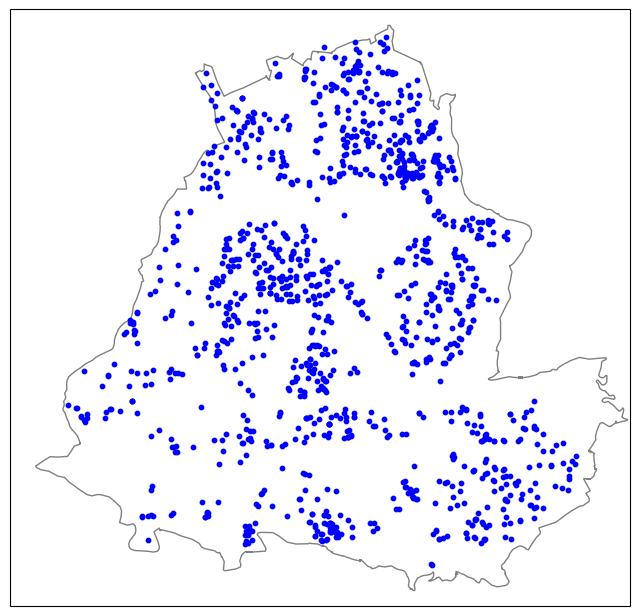

In [ ]:
 #Proyección del mapa de floridablanca

url = 'https://raw.githubusercontent.com/fmoreno4/cd-files/main/'
file_list = ["68276_urbano.cpg", "68276_urbano.dbf", "68276_urbano.prj", "68276_urbano.shp", "68276_urbano.shx"]
for file in file_list:
    urllib.request.urlretrieve(url+file, file)

subplot_kw = dict(projection=ccrs.PlateCarree())

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=subplot_kw)

# Puntos Floridablanca
lower_lon = -73.1215
upper_lon = -73.0732
lower_lat = 7.054
upper_lat = 7.1005

ax.set_extent([lower_lon, upper_lon, lower_lat, upper_lat])

reader = shapereader.Reader('68276_urbano.shp')
for poli in reader.geometries():
    ax.add_geometries([poli], ccrs.PlateCarree(), facecolor='white', edgecolor='gray')

ax.scatter(df_coordenadas['longitud'], df_coordenadas['latitud'], zorder=10, c='b', s=10)

plt.show()

In [ ]:
df_coordenadas.min(axis=0)

latitud          7.057170
longitud       -73.116966
x           707988.571579
y           780501.634040
dtype: float64

In [ ]:
df_coordenadas.max(axis=0)

latitud          7.098318
longitud       -73.077385
x           712363.886503
y           785051.175930
dtype: float64

In [ ]:
def matriz_resolucion (min_X, max_X, min_Y, max_Y, resolucion):
  matriz_cols_X = math.ceil(((max_X-min_X)/resolucion))
  matriz_rows_Y = math.ceil(((max_Y-min_Y)/resolucion))

  return matriz_cols_X, matriz_rows_Y

In [ ]:
resolucion = 10
cols_X, rows_Y = matriz_resolucion(df_coordenadas['x'].min(), df_coordenadas['x'].max(), df_coordenadas['y'].min(), df_coordenadas['y'].max(), resolucion)
print(cols_X, rows_Y)

438 455


In [ ]:
matriz_ceros = np.zeros((rows_Y, cols_X))
matriz_ceros

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
for index, fila in df_coordenadas.iterrows():
      X = fila['x'] # Obtener el valor de X de la fila correspondiente
      Y = fila['y'] # Obtener el valor de Y de la columna correspondiente
      resultado_X = math.floor((X - df_coordenadas['x'].min()) / resolucion)
      resultado_Y = math.floor((Y - df_coordenadas['y'].min()) / resolucion)
      matriz_ceros [resultado_Y, resultado_X]+=1

print(matriz_ceros)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
np.sum(matriz_ceros)

1262.0

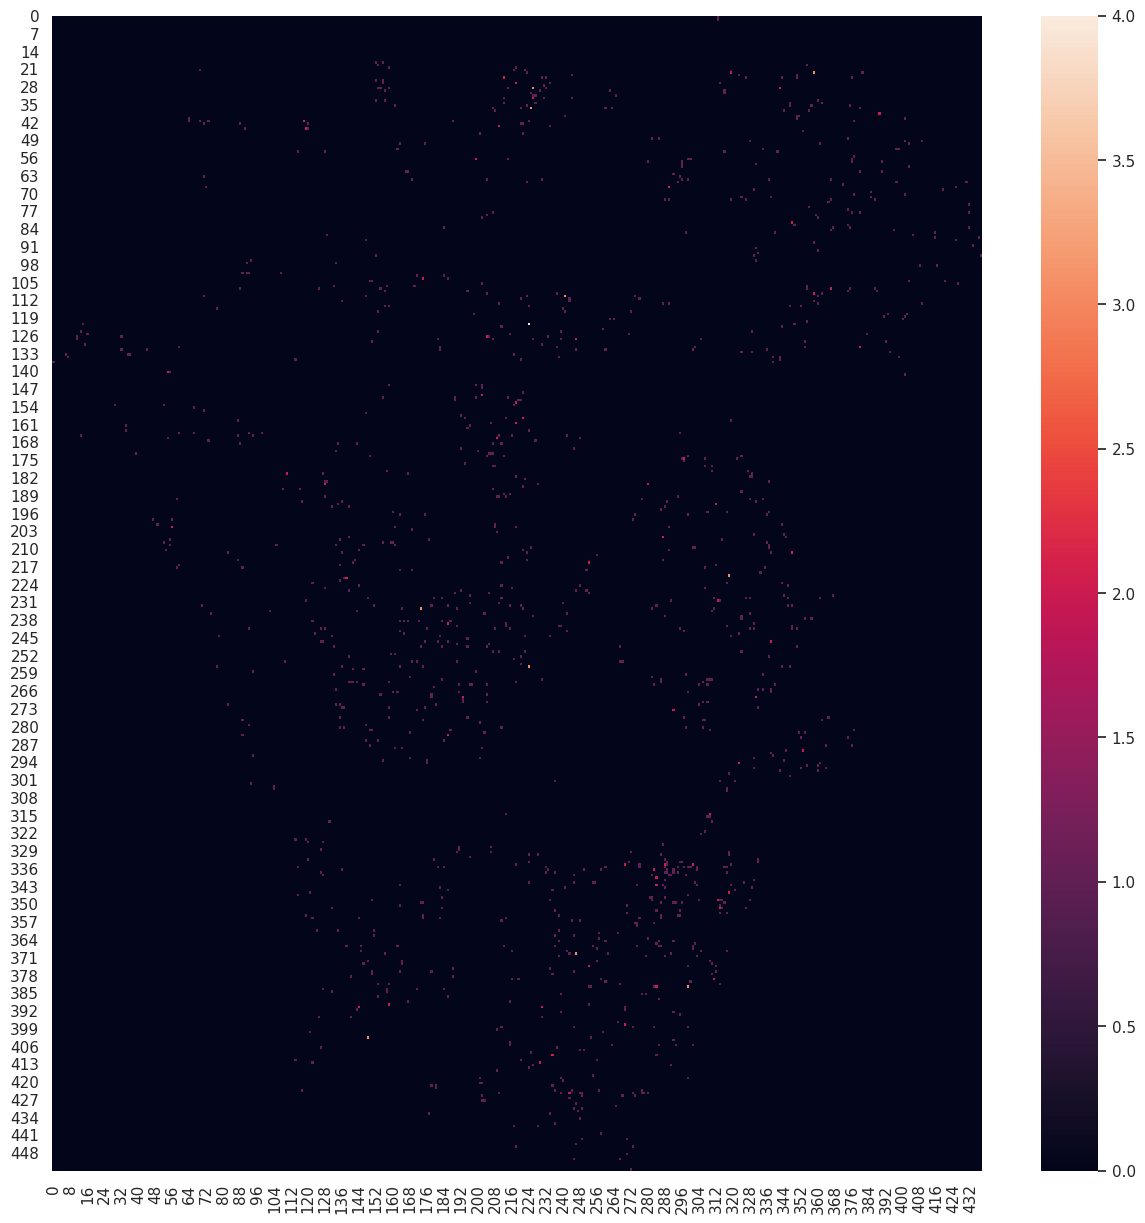

In [ ]:
import seaborn as sns
sns.set(rc = {'figure.figsize':(15,15)})
p = sns.heatmap(matriz_ceros)

In [ ]:
def distancia(x1,y1,x2,y2):
  return math.sqrt((x2-x1)**2 + (y2-y1)**2)

In [ ]:
radio_circulo = 100
n_resolucion = math.ceil(radio_circulo/resolucion)

In [ ]:
matriz_densidad = np.zeros((rows_Y, cols_X))

In [ ]:
def kernel(tipo_f, distancia, radio):
  if (tipo_f == "uniforme"):
    resultado = 1
  elif (tipo_f == "triangular"):
    resultado = 1-(distancia/radio)
  elif (tipo_f == "gauss"):
    resultado = math.exp(-(distancia**2/(2*radio**2)))
  elif (tipo_f == "epane"):
    resultado = 1-(distancia/radio)**2
  elif (tipo_f == "exponencial"):
    resultado = math.exp(-(distancia/radio))
  elif (tipo_f == "coseno"):
    resultado = math.cos((math.pi*distancia)/(2*radio))
  return resultado

In [ ]:
#las funciones kernel son: uniforme, triangular, gauss, epane, exponencial y coseno
kernel("exponencial",85,100)

0.4274149319487267

In [ ]:
for i in range(rows_Y):
    Y_inicial, Y_final = np.clip([i - n_resolucion, i + n_resolucion], 0, rows_Y - 1)
    for j in range(cols_X):
        X_inicial, X_final = np.clip([j - n_resolucion, j + n_resolucion], 0, cols_X - 1)
        suma = 0
        for k in range(Y_inicial, Y_final + 1):
            for l in range(X_inicial, X_final + 1):
                d_centro = distancia(i, j, k, l)
                if (d_centro <= n_resolucion):
                    suma += matriz_ceros[k][l]*(kernel("exponencial",(d_centro*resolucion),radio_circulo))

        matriz_densidad[i][j] = suma/(math.pi*radio_circulo**2)

In [ ]:
matriz_densidad

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

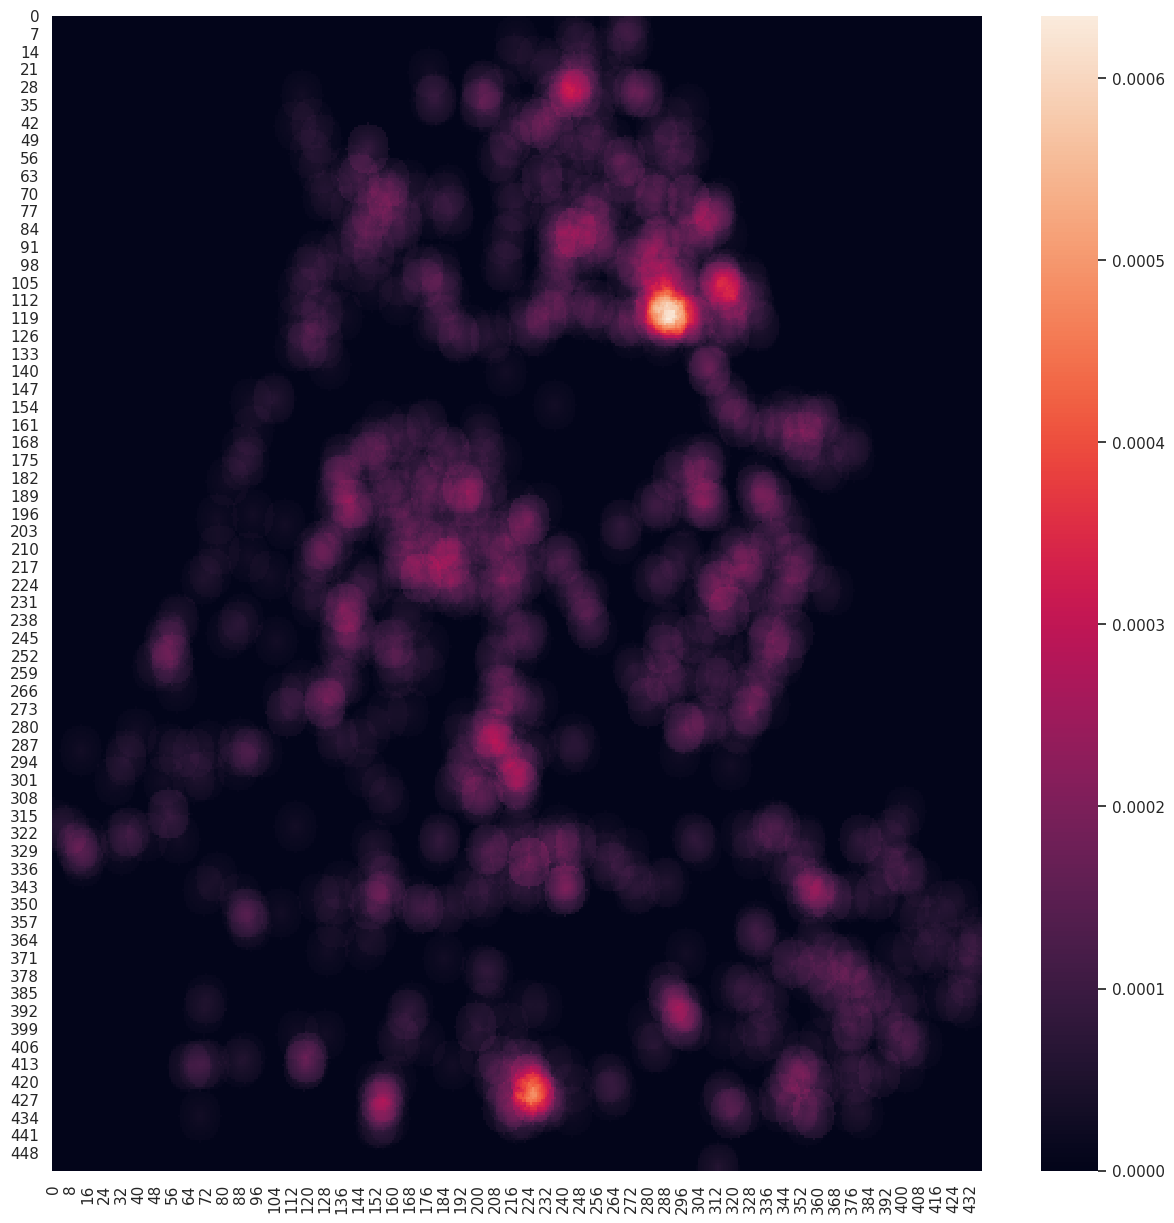

In [ ]:
#Mapa Normal al invertir
matriz_densidad_invertida = np.flipud(matriz_densidad)
import seaborn as sns
sns.set(rc = {'figure.figsize':(15,15)})
p = sns.heatmap(matriz_densidad_invertida)

In [ ]:
import colorsys

def rgb_a_hsv(r, g, b):
  (h, s, v) = colorsys.rgb_to_hsv(r, g, b)
  return (h, s, v)

def hsv_a_rgb(h, s, v):
  (r, g, b) = colorsys.hsv_to_rgb(h, s, v)
  r = int(r)
  g = int(g)
  b = int(b)
  return (r, g, b)

In [ ]:
#rgb

def pintar_color(rojo,verde,azul):
  img  = Image.new('RGB', (300, 25))
  draw = ImageDraw.Draw(img)
  draw.rectangle([(0,0), img.size], fill = (rojo,verde,azul))
  display(img)


#Color inicial (red,green,blue)
r_inicial = 0
g_inicial = 255
b_inicial = 0
hsv_inicial = rgb_a_hsv(r_inicial, g_inicial, b_inicial)

#color final (red,green,blue)

r_final = 255
g_final = 0
b_final = 0
hsv_final = rgb_a_hsv(r_final, g_final, b_final)

n_colores = 10

for i in range(n_colores):
  h = (hsv_inicial[0]+i*((hsv_final[0]-hsv_inicial[0]) / (n_colores-1)))
  s = (hsv_inicial[1]+i*((hsv_final[1]-hsv_inicial[1]) / (n_colores-1)))
  v = (hsv_inicial[2]+i*((hsv_final[2]-hsv_inicial[2]) / (n_colores-1)))

  (r,g,b) = hsv_a_rgb(h,s,v)
  pintar_color(r,g,b)

In [ ]:
def gama_colores(color_ini, color_fin, n_color):
  t_ini = rgb_a_hsv(color_ini[0], color_ini[1], color_ini[2])
  h_ini = t_ini[0]
  s_ini = t_ini[1]
  v_ini = t_ini[2]

  t_fin = rgb_a_hsv(color_fin[0], color_fin[1], color_fin[2])
  h_fin = t_fin[0]
  s_fin = t_fin[1]
  v_fin = t_fin[2]

  lista_colores = []
  for i in range(n_colores):
    h = h_ini + (i * (h_fin - h_ini) / (n_colores - 1))
    s = s_ini + (i * (s_fin - s_ini) / (n_colores - 1))
    v = v_ini + (i * (v_fin - v_ini) / (n_colores - 1))
    t_rgb = hsv_a_rgb(h, s, v)
    lista_colores.append((t_rgb[0], t_rgb[1], t_rgb[2]))

  return lista_colores

In [ ]:
lista_colores = gama_colores((255,255,0), (255,0,0), 10)
print(lista_colores)

[(255, 255, 0), (255, 226, 0), (255, 198, 0), (255, 170, 0), (255, 141, 0), (255, 113, 0), (255, 84, 0), (255, 56, 0), (255, 28, 0), (255, 0, 0)]


In [ ]:
#generar la imagen
!pip install Pillow
from IPython.display import display

In [ ]:
matriz_sin_ceros = matriz_densidad[matriz_densidad != 0]

min_densidad = matriz_sin_ceros.min()
max_densidad = matriz_sin_ceros.max()

print(min_densidad)
print(max_densidad)

1.1709966304863832e-05
0.0006344395230289762


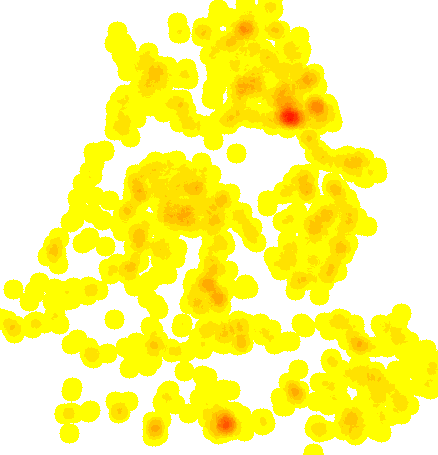

In [ ]:
width = (cols_X)
height = (rows_Y)

image = Image.new("RGB", (width, height))

for y in range(height):
    for x in range(width):
        density_value = matriz_densidad_invertida[y][x]
        if (density_value != 0):
         color_index = int((density_value - min_densidad) / (max_densidad - min_densidad) * (len(lista_colores) - 1))
         color = lista_colores[color_index]
        else:
         color = (255,255,255)
        image.putpixel((x, y), color)


display(image)